# Classify handwritten digits using Neural Network

In [1]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as ds
import torch.nn.functional as f
import matplotlib.pyplot as plt
import numpy as np

In [27]:
# define a function to plot accuracy and loss

def plot_accuracy_loss(train_result):
    plt.subplot(2,1,1)
    plt.plot(train_result['training_loss'], 'r')
    plt.ylabel('loss')
    plt.title('train loss iterations')
    plt.subplot(2,1,2)
    plt.plot(train_result['valid_accuracy'], 'r')
    plt.ylabel('accuracy')
    plt.xlabel('epochs')
    plt.show()

In [12]:
# define a function to plot model parameters

def print_model_parameters(model):
    count = 0
    for ele in model.state_dict():
        count += 1
        if count % 2 != 0:
            print("The following are the parameters for the layer ", count // 2 + 1)
        if ele.find("bias") != -1:
            print("The size of bias: ", model.state_dict()[ele].size())
        else:
            print("The size of weights: ", model.state_dict()[ele].size())

In [3]:
# define a function to display data

def show_data(data_sample):
    plt.imshow(data_sample.numpy().reshape(28,28), cmap='gray')
    plt.show()

## Neural Network Module and Training Function

In [16]:
# define a Neural Network class

class Net(nn.Module):
    # Constructor
    def __init__(self, D_in, H, D_out):
        super(Net, self).__init__()
        self.linear1 = nn.Linear(D_in, H)
        self.linear2 = nn.Linear(H, D_out)

    # Prediction
    def forward(self,x):
        x = torch.sigmoid(self.linear1(x))
        x = self.linear2(x)
        return x

In [17]:
# define a training function to train the model

def train(model, criterion, train_loader, valid_loader, optimizer, epochs=100):
    i=0
    use_dic = {'training_loss':[], 'valid_accuracy':[]}
    for epoch in range(epochs):
        for i, (x,y) in enumerate(train_loader):
            optimizer.zero_grad()
            z = model(x.view(-1, 28*28))
            loss = criterion(z,y)
            loss.backward()
            optimizer.step()
            # loss for every iteration
            use_dic['training_loss'].append(loss.data.item())

        correct = 0
        for x,y in valid_loader:
            # validition
            z = model(x.view(-1, 28*28))
            _, label = torch.max(z, 1)
            correct += (label == y).sum().item()

        accuracy = 100 * (correct / len(validation_dataset))
        use_dic['valid_accuracy'].append(accuracy)

    return use_dic

## Make some Data

In [18]:
# create training dataset
train_dataset = ds.MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())

In [19]:
# create validating dataset
validation_dataset = ds.MNIST(root='./data', train=False, download=True, transform=transforms.ToTensor())

In [20]:
# Create data loader for both train and validation dataset
from torch.utils.data import DataLoader
train_loader = DataLoader(dataset=train_dataset, batch_size=2000, shuffle=True)
valid_loader = DataLoader(dataset=validation_dataset, batch_size=5000, shuffle=True)

## Define the Neural Network, Optimizer, criterion and train the model

In [21]:
# create criterion function
criterion = nn.CrossEntropyLoss()

In [22]:
# create the model with 100 neurons
 
input_dim = 28 * 28
hidden_dim = 100
output_dim = 10

model = Net(input_dim,hidden_dim,output_dim)

In [23]:
# print the parameters
print_model_parameters(model)

The following are the parameters for the layer  1
The size of weights:  torch.Size([100, 784])
The size of bias:  torch.Size([100])
The following are the parameters for the layer  2
The size of weights:  torch.Size([10, 100])
The size of bias:  torch.Size([10])


In [24]:
# Set the learning rate and the optimizer
optimizer = torch.optim.SGD(model.parameters(), lr = 0.01)

In [25]:
# train the model
traning_results = train(model, criterion, train_loader, valid_loader,optimizer, epochs=30)

## Analyze Results

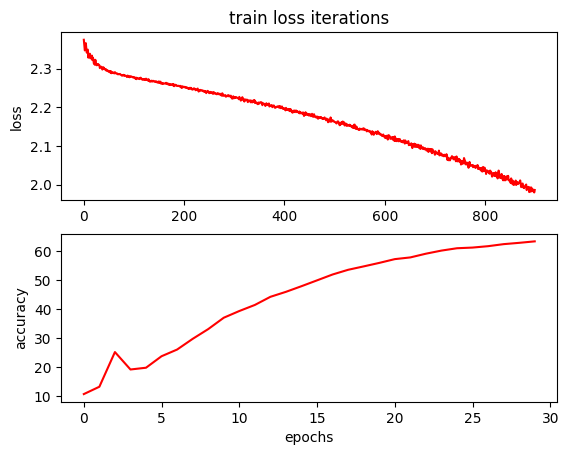

In [28]:
plot_accuracy_loss(traning_results)

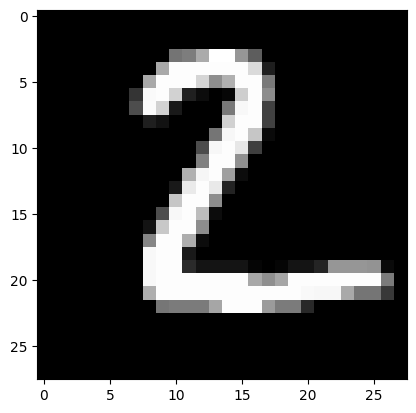

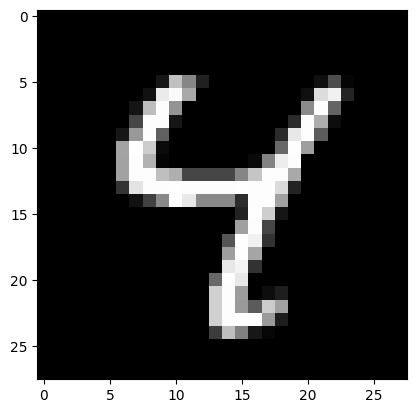

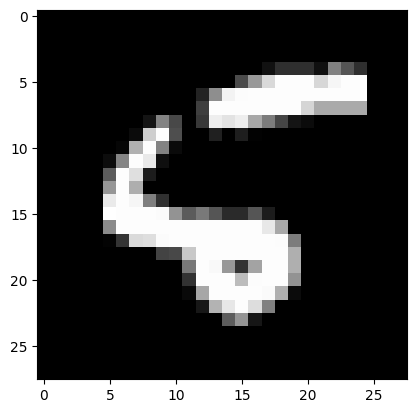

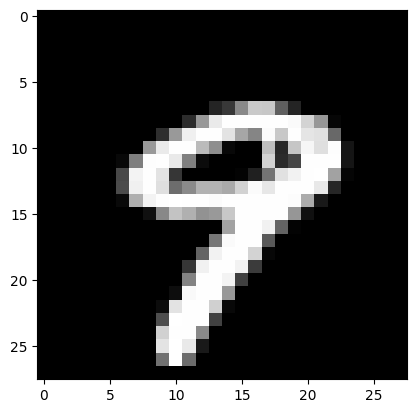

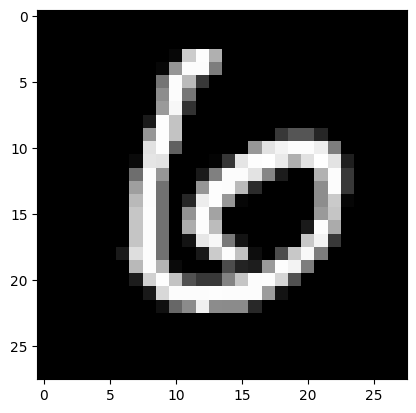

In [29]:
# plot the first five misclassifified samples

count = 0
for x,y in validation_dataset:
    z = model(x.reshape(-1, 28*28))
    _,yhat = torch.max(z, 1)
    if yhat != y:
        show_data(x)
        count += 1
    if count >= 5 :
        break